<a href="https://colab.research.google.com/github/oooinr4018-web/-1/blob/main/ESAA_1012_%EA%B3%BC%EC%A0%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 2.4. 파이토치 코드 맛보기

칼럼: price, maint, doors, persons, lug_capacity, safety, output (차 상태)

In [2]:
!pip install matplotlib
!pip install seaborn
!pip install scikit-learn

In [3]:
!pip install--upgrade matplotlib--use-feature=2020-resolver
!pip install --upgrade seaborn --use-feature=2020-resolver
!pip install --upgrade scikit-learn --use-feature=2020-resolver

ERROR: unknown command "install--upgrade" - maybe you meant "install"

Usage:   
  pip3 install [options] <requirement specifier> [package-index-options] ...
  pip3 install [options] -r <requirements file> [package-index-options] ...
  pip3 install [options] [-e] <vcs project url> ...
  pip3 install [options] [-e] <local project path> ...
  pip3 install [options] <archive url/path> ...

option --use-feature: invalid choice: '2020-resolver' (choose from 'fast-deps', 'truststore', 'no-binary-enable-wheel-cache')

Usage:   
  pip3 install [options] <requirement specifier> [package-index-options] ...
  pip3 install [options] -r <requirements file> [package-index-options] ...
  pip3 install [options] [-e] <vcs project url> ...
  pip3 install [options] [-e] <local project path> ...
  pip3 install [options] <archive url/path> ...

option --use-feature: invalid choice: '2020-resolver' (choose from 'fast-deps', 'truststore', 'no-binary-enable-wheel-cache')


In [5]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [17]:
dataset=pd.read_csv('car.data')
cols = ['price', 'maint', 'doors', 'persons', 'lug_capacity', 'safety', 'output']

dataset = pd.read_csv('car.data', names=cols)

display(dataset.head())

,price,maint,doors,persons,lug_capacity,safety,output
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


<Axes: ylabel='count'>

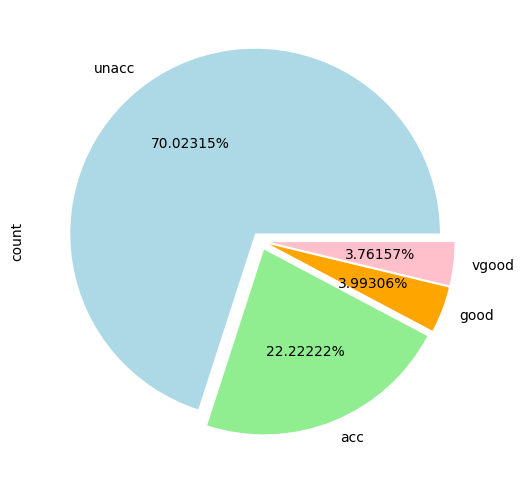

In [18]:
fig_size=plt.rcParams["figure.figsize"]
fig_size[0]=8
fig_size[1]=6
plt.rcParams["figure.figsize"]=fig_size
dataset.output.value_counts().plot(kind='pie', autopct='%0.05f%%',
                                   colors=['lightblue', 'lightgreen', 'orange', 'pink'], explode=(0.05, 0.05, 0.05, 0.05))

In [20]:
categorical_columns=['price', 'maint', 'doors', 'persons', 'lug_capacity', 'safety']

for category in categorical_columns:
  dataset[category]=dataset[category].astype('category')

price=dataset['price'].cat.codes.values
maint=dataset['maint'].cat.codes.values
doors=dataset['doors'].cat.codes.values
persons=dataset['persons'].cat.codes.values
lug_capacity=dataset['lug_capacity'].cat.codes.values
safety=dataset['safety'].cat.codes.values

categorical_data=np.stack([price, maint, doors, persons, lug_capacity, safety], 1)
categorical_data[:10] # 합친 넘파이 배열 중 열 개의 행을 출력하여 보여 줍니다.


array([[3, 3, 0, 0, 2, 1],
       [3, 3, 0, 0, 2, 2],
       [3, 3, 0, 0, 2, 0],
       [3, 3, 0, 0, 1, 1],
       [3, 3, 0, 0, 1, 2],
       [3, 3, 0, 0, 1, 0],
       [3, 3, 0, 0, 0, 1],
       [3, 3, 0, 0, 0, 2],
       [3, 3, 0, 0, 0, 0],
       [3, 3, 0, 1, 2, 1]], dtype=int8)

- 데이터 전처리

- astype() 메서드로 데이터를 범주형 타입으로 변환 -> 텐서로 변환

범주형 데이터 -> dataset -> 넘파이 배열 -> 텐서

- cat.codes: 범주형 데이터를 숫자로 변환

- np.stack: 두 개 이상의 넘파이 객체 합칠 때 사용 (새로운 축으로 합침, 합치려는 두 넘파이 배열의 차원이 다름.)

- np.concatenate: 축 기준 두 개 배열 연결



In [21]:
categorical_data=torch.tensor(categorical_data, dtype=torch.int64)
categorical_data[:10]

tensor([[3, 3, 0, 0, 2, 1],
        [3, 3, 0, 0, 2, 2],
        [3, 3, 0, 0, 2, 0],
        [3, 3, 0, 0, 1, 1],
        [3, 3, 0, 0, 1, 2],
        [3, 3, 0, 0, 1, 0],
        [3, 3, 0, 0, 0, 1],
        [3, 3, 0, 0, 0, 2],
        [3, 3, 0, 0, 0, 0],
        [3, 3, 0, 1, 2, 1]])

- 레이블로 사용할 칼럼에 대해서도 텐서로 변환


In [22]:
outputs=pd.get_dummies(dataset.output)
outputs=outputs.values
outputs=torch.tensor(outputs).flatten() # 1차원 텐서로 변환

print(categorical_data.shape)
print(outputs.shape)


torch.Size([1728, 6])
torch.Size([6912])


- get_dummies를 이용하여 넘파이 배열로 변환

- get_dummies: 가변수(dummy variable)로 만들어 주는 함수

-> 문자를 숫자 (0,1)로 변환

In [23]:
categorical_column_sizes=[len(dataset[column].cat.categories) for column in categorical_columns]
categorical_embedding_sizes=[(col_size, min(50, (col_size+1)//2)) for col_size in
                             categorical_column_sizes]
print(categorical_embedding_sizes)

[(4, 2), (4, 2), (4, 2), (3, 2), (3, 2), (3, 2)]


- (모든 범주형 칼럼의 고유 값 수, 차원의 크기) 형태의 배열 출

- 워드 임베딩: 유사한 단어끼리 유사하게 이코딩되도록 표현하는 방법

- 높은 차원의 임베딩일수록 단어 간 세부 관계 잘 파악 가능

- 넘파이 배열 -> 단일 숫자 -> N차원

-배열을 N차원으로 변환하기 위해 범주형 칼럼에 대한 임베딩 크기 정의

(칼럼의 고유 값 수를 2로 나누는 것 많이 사용)



In [24]:
total_records=1728
test_records=int(total_records*.2) # 전체 데이터 중 20%를 테스트 용도로 사용

categorical_train_data=categorical_data[:total_records-test_records]
categorical_test_data=categorical_data[total_records-test_records:total_records]
train_outputs=outputs[:total_records-test_records]
test_outputs=outputs[total_records-test_records:total_records]

- 데이터셋을 훈련, 테스트 용도로 분리

In [25]:
print(len(categorical_train_data))
print(len(train_outputs))
print(len(categorical_test_data))
print(len(test_outputs))

1383
1383
345
345


In [41]:
class Model(nn.Module):
  def __init__(self, embedding_size, output_size, layers, p=0.4):
    super().__init__()
    self.all_embeddings=nn.ModuleList([nn.Embedding(ni, nf) for ni, nf in embedding_size])
    self.embedding_dropout=nn.Dropout(p)

    all_layers=[]
    num_categorical_cols=sum((nf for ni, nf in embedding_size))
    input_size=num_categorical_cols # 입력층의 크기를 찾기 위해 범주형 칼럼 개수를 input_size 변수에 저장

    for i in layers:
      all_layers.append(nn.Linear(input_size, i))
      all_layers.append(nn.ReLU(inplace=True))
      all_layers.append(nn.BatchNorm1d(i))
      all_layers.append(nn.Dropout(0))
      input_size=i

    all_layers.append(nn.Linear(layers[-1], output_size))
    self.layers=nn.Sequential(*all_layers) # 신경망의 모든 계층이 순차적으로 실행되도록 모든 계층에 대한 목록을 nn.Sequential 클래스로 전달

  def forward(self, x_categorical):
    embeddings=[]
    for i, e in enumerate(self.all_embeddings):
      embeddings.append(e(x_categorical[:,i]))

    x=torch.cat(embeddings, 1) # 넘파이의 concatenate와 같지만 대상이 텐서가 됩니다.
    x=self.embedding_dropout(x)
    x=self.layers(x)

    return x

- 모델의 네트워크 생성

- 클래스 형태로 구현되는 모델은 nn.Module을 상속받음.

- __init__(): 모델에서 사용될 파라미터, 신경망 초기화

( __init__()에서 전달되는 매개변수: self, embedding_size, output_size, layers, p)

self: 첫 번째 파라미터, 자기 자신

embedding_size: 범주형 칼럼의 임베딩 크기

output_size: 출력층의 크기

layers: 모든 계층에 대한 목록

p: 드롭아웃 (기본값 0.5)

- super().__init__(): 부모 클래스(nn.Module)에 접근할 때 사용

- all_layers 목록에 각 계층 추가

Linear: 입력 데이터에 선형 변환을 진행한 결과

ReLU: 활성화 함수로 사용

BatchNorm1d: 배치 정규화 용도로 사용

Dropout: 과적합 방지에 사용

- forward()함수: 학습 데이터를 입력받아서 연산 진행

(모델 객체, 데이터 함께 호출)



In [42]:
model=Model(categorical_embedding_sizes, 4, [200,100,50], p=0.4)
print(model)

Model(
  (all_embeddings): ModuleList(
    (0-2): 3 x Embedding(4, 2)
    (3-5): 3 x Embedding(3, 2)
  )
  (embedding_dropout): Dropout(p=0.4, inplace=False)
  (layers): Sequential(
    (0): Linear(in_features=12, out_features=200, bias=True)
    (1): ReLU(inplace=True)
    (2): BatchNorm1d(200, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Dropout(p=0, inplace=False)
    (4): Linear(in_features=200, out_features=100, bias=True)
    (5): ReLU(inplace=True)
    (6): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): Dropout(p=0, inplace=False)
    (8): Linear(in_features=100, out_features=50, bias=True)
    (9): ReLU(inplace=True)
    (10): BatchNorm1d(50, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): Dropout(p=0, inplace=False)
    (12): Linear(in_features=50, out_features=4, bias=True)
  )
)


- 이는 모델에 대한 구조

In [43]:
loss_function=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(model.parameters(), lr=0.001)

- 모델 훈련시키기 전 손실 함수, 옵티마이저 정의

- 크로스 엔트로피 손실 함수: 데이터 분류

- 옵티마이저로 아담 사용

In [44]:
if torch.cuda. is_available():
  device=torch.device('cuda') # GPU가 있다면 GPU를 사용
else:
  device=torch.device('cpu') # GPU가 없다면 CPU를 사용

- 파이토치: GPU에 최적화된 딥러닝 프레임워크



In [45]:
epochs=500
aggregated_losses=[]
train_outputs=train_outputs.to(device=device, dtype=torch.int64)

for i in range(epochs): # for문은 500회 반복되며, 각 반복마다 손실 함수가 오차를 계산
  i+=1
  y_pred=model(categorical_train_data).to(device)
  single_loss=loss_function(y_pred, train_outputs)
  aggregated_losses.append(single_loss) # 반복할 떄마다 오차를 aggregated_losses에 추가

  if i%25==1:
    print(f'epoch: {i:3} loss: {single_loss.item():10.8f}')

  optimizer.zero_grad()
  single_loss.backward() # 가중치를 업데이트하기 위해 손실 함수의 backward() aptjem ghcnf
  optimizer.step() # 옵티마이저 함수의 step() 메서드를 이용하여 기울기 업데이트

print(f'epoch: {i:3} loss: {single_loss.item():10.10f}') # 오차가 25 에포크마다 출력



epoch:   1 loss: 1.57755518
epoch:  26 loss: 1.38293850
epoch:  51 loss: 1.24324679
epoch:  76 loss: 1.04198396
epoch: 101 loss: 0.84358704
epoch: 126 loss: 0.70397121
epoch: 151 loss: 0.63348377
epoch: 176 loss: 0.59175450
epoch: 201 loss: 0.57085145
epoch: 226 loss: 0.55764747
epoch: 251 loss: 0.53105807
epoch: 276 loss: 0.51770085
epoch: 301 loss: 0.48307556
epoch: 326 loss: 0.48922801
epoch: 351 loss: 0.47006735
epoch: 376 loss: 0.47876272
epoch: 401 loss: 0.46905610
epoch: 426 loss: 0.47062752
epoch: 451 loss: 0.44652888
epoch: 476 loss: 0.43842453
epoch: 500 loss: 0.4482082427


- 코드 실행 시, 25 에포크마다 출력된 오차 정보 보여줌.

- 학습 완료

In [46]:
test_outputs=test_outputs.to(device=device, dtype=torch.int64)
with torch.no_grad():
  y_val=model(categorical_test_data)
  loss=loss_function(y_val, test_outputs)
print(f'Loss: {loss:.8f}')

Loss: 0.45639017


- 테스트 데이터셋으로 예측 진행

- categorical_test_data 데이터셋을 모델에 적용

- 테스트 용도의 데이터셋에 대한 손실 값 ( ~= 훈련 데이터셋에서 도출된 손실 값)

-> 과적합 발생 X



In [47]:
print(y_val[:5])

tensor([[ 3.4741, -0.5898, -1.8651, -2.0772],
        [ 2.6917,  1.0866, -2.9227, -3.3001],
        [ 2.7627,  1.3515, -2.9518, -3.2624],
        [ 2.3545,  2.8848, -2.7459, -2.4611],
        [ 3.0660,  1.9852, -3.1548, -3.4238]])


- 모델이 얼마나 잘 예측하는지 확인 (처음 다섯 개의 값 출력)

In [48]:
y_val=np.argmax(y_val, axis=1)
print(y_val[:5])

tensor([0, 0, 0, 1, 0])


- 목록에서 가장 큰 값을 갖는 인덱스 알아보기



In [49]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
print(confusion_matrix(test_outputs, y_val))
print(classification_report(test_outputs, y_val))
print(accuracy_score(test_outputs, y_val))

[[244  15]
 [ 54  32]]
              precision    recall  f1-score   support

           0       0.82      0.94      0.88       259
           1       0.68      0.37      0.48        86

    accuracy                           0.80       345
   macro avg       0.75      0.66      0.68       345
weighted avg       0.78      0.80      0.78       345

0.8


- sklearn.metrics 모듈의 classification_report, confusion_matrix, accuracy_score 클래스 -> 정확도, 정밀도, 재현율

- True Positive: 모델이 1이라고 예측했는데 실제 값도 1인 경우

- True Negative: 모델이 0이라고 예측했는데 실제 값도 0인 경우

- Flase Positive: 모델이 1이라고 예측했는데, 실제 값은 0인 경우

- Flase Negative: 모델이 0이라고 예측했는데 실제 값은 1인 경우

- 정확도: 전체 예측 건수에서 정답을 맞힌 건수의 비율

(True Positive+True Negative)/(True Positive+True Negative+False Positive+False Negative)

- 재현율: 실제로 정답이 1이라고 할 때 모델도 1로 예측한 비율

(True Positive/(True Positive+False Negative)

- 정밀도: 모델이 1이라고 예측한 것 중 실제로 정답이 1인 비율

(True Positive/(True Positive+False Positive)

- F1-스코어: 정밀도왖 ㅐ현율의 트레이드오프 문제를 해결하기위해 정밀도와 재현율의 조화평균 이용한 것

2*(Precision x Recall)/(Precision + Recall)